# Compressed sensing of audio, images

Executed in python 3.14.3


In [1]:
import os, sys

import numpy as np
import matplotlib.pyplot as plt
from scipy.fftpack import dct, idct
from scipy.ndimage import zoom
import cvxpy as cp

In [2]:
# taken from https://github.com/avirmaux/CoSaMP/tree/master, in lieu of finding a package that works

def cosamp(phi, u, s, epsilon=1e-10, max_iter=1000):
    """
    Return an `s`-sparse approximation of the target signal
    Input:
        - phi, sampling matrix
        - u, noisy sample vector
        - s, sparsity
    """
    a = np.zeros(phi.shape[1])
    v = u
    it = 0 # count
    halt = False
    while not halt:
        it += 1
        print("Iteration {}\r".format(it), end="")
        
        y = np.dot(np.transpose(phi), v)
        omega = np.argsort(y)[-(2*s):] # large components
        omega = np.union1d(omega, a.nonzero()[0]) # use set instead?
        phiT = phi[:, omega]
        b = np.zeros(phi.shape[1])
        # Solve Least Square
        b[omega], _, _, _ = np.linalg.lstsq(phiT, u)
        
        # Get new estimate
        b[np.argsort(b)[:-s]] = 0
        a = b
        
        # Halt criterion
        v_old = v
        v = u - np.dot(phi, a)

        halt = (np.linalg.norm(v - v_old) < epsilon) or \
            np.linalg.norm(v) < epsilon or \
            it > max_iter
        
    return a

## 1 - audio signals

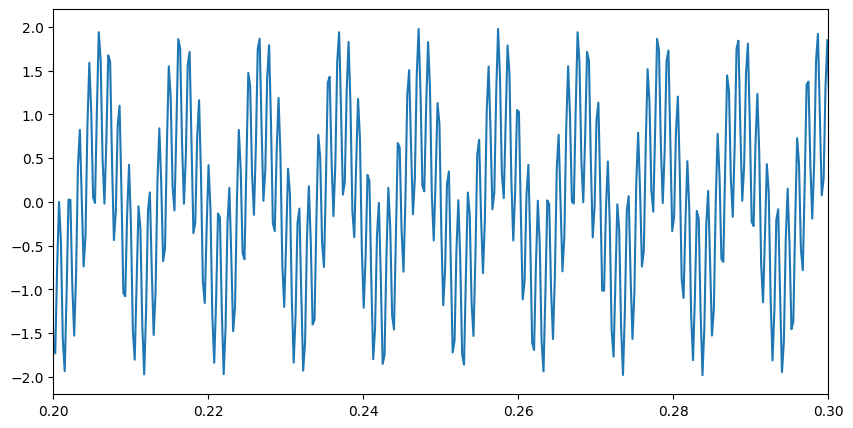

In [3]:
NUM_POINTS = 2**12

t = np.linspace(0, 1, NUM_POINTS)

# change below to change the specific form. this is the same as the textbook - 2 tone signal
x = np.cos(2*97*np.pi*t) + np.cos(2*777*np.pi*t)

plt.figure(figsize=(10,5))
plt.plot(t, x)
plt.xlim(0.2, 0.3)
plt.show()

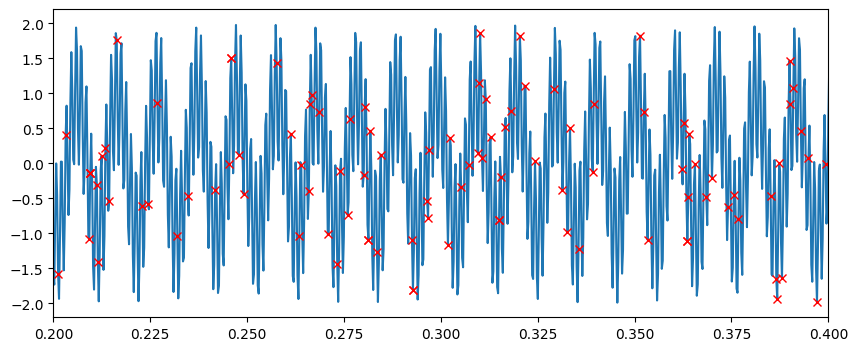

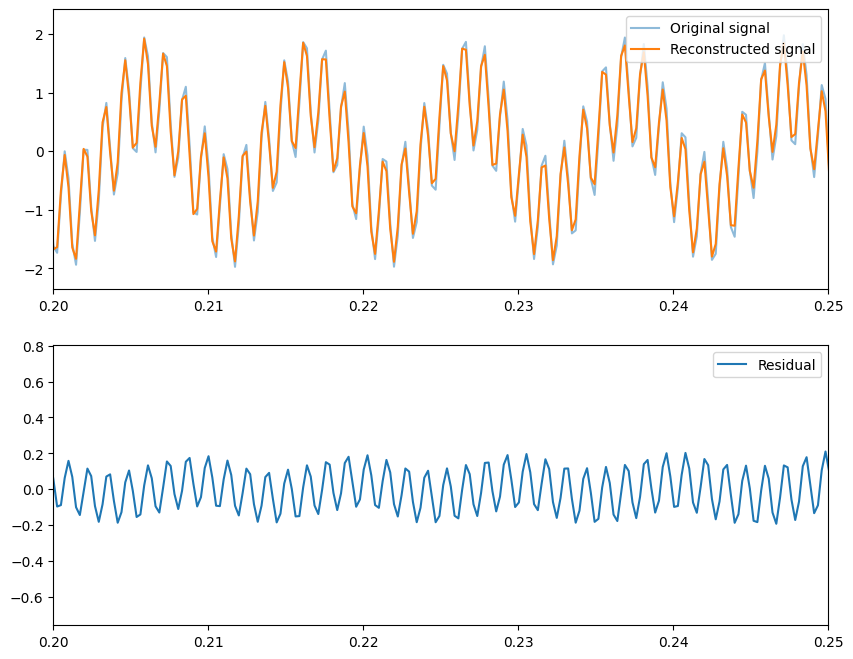

In [4]:
xt = np.fft.fft(x)
# Power spectral density
PSD = xt * np.conjugate(xt) / NUM_POINTS

# take a random sample in line with sample_count
sample_count = 500
sample_count = int(sample_count) # ensure no float

selections = np.round(np.random.rand(sample_count, 1) * NUM_POINTS)
selections = [int(e[0]) for e in selections]

y = x[selections]
plt.figure(figsize=(10, 4))
plt.plot(t, x)
plt.plot(t[selections], y, 'x', color='red')
plt.xlim(0.2, 0.4)
plt.show()

# create generic Psi
# make a NxN identity matrix
identity = np.eye(NUM_POINTS, NUM_POINTS)
# implement discrete cosign transform on identity matrix (from scipy.fftpack)
psi = dct(identity)
# take theta, our p * n matrix featuring what measurements are made 
# selections is a vector representing where samples have been made
theta = psi[selections, :]

# apply cosamp algorithm
s = cosamp(theta, y, 4)

x_r = idct(s)
lim = (0.2, 0.25)
plt.figure(figsize=(10, 8))
plt.subplot(2, 1, 1)
plt.plot(t, x, alpha=0.5, label='Original signal')
plt.plot(t, x_r, label='Reconstructed signal')
plt.legend()
plt.xlim(*lim)
plt.subplot(2, 1, 2)
plt.plot(t, x-x_r, label='Residual')
plt.legend()
plt.xlim(*lim)
plt.show()


## 2 - formalising 

In [5]:
def take_samples(x, samples):
    '''
    returns a list of sampled indicies for X, such that x[indicies] returns only those samples'''
    selections = np.round(np.random.rand(samples, 1) * len(x)-1)
    selections = [int(e[0]) for e in selections]
    return selections

def reconstruct(y, n, p, sparsity=5, epsilon=1e-10, max_iter=1000, mode='cosamp'):
    '''
    for a sampling y, with n maximum spaces in the dataset and sample vector p, computes and returns the reconstructed signal x'''
    psi = dct(np.eye(n, n))
    theta = psi[p, :]
    if mode=='cosamp':
        s = cosamp(theta, y, sparsity, epsilon, max_iter)
    elif mode=='cvx':
        s_l1 = cp.Variable((n, 1))
        obj = cp.Minimize(cp.norm(s_l1, 1))
        cons = [theta @ s_l1 == y]
        problem = cp.Problem(obj, cons)
        problem.solve()
        s = s_l1.value


    return idct(s)

## 3 - images

i've got a directory `./testdata/` with various images that i've set not to include into the git repo - up to you to include your own data.

In [ ]:
def plot_nice_image(img, pow=None, darkBack = True, invert=False, cmap:tuple = None):
    cs = ('Reds', 'Greens', 'Blues')
    if cmap != None:
        cs = cmap
    if darkBack:
        backing = np.ones(shape=(img.shape[0], img.shape[0]))
        plt.imshow(backing, cmap='gray')
    for n in range(3):
        imgsel = img[:,:,n]
        if darkBack:
            achannel = img[:,:,n]
            achannel = np.where(achannel > 0, achannel, 0)
            if pow != None:
                if type(pow) in (int, float):
                    achannel = np.pow(achannel, pow)
                else:
                    achannel = np.pow(achannel, pow[n])
            if invert:
                imgsel = 1-imgsel
            plt.imshow(imgsel, cmap=cs[n], alpha=achannel)
        else:
            if invert:
                imgsel = 1-imgsel
            plt.imshow(imgsel, cmap=cs[n], alpha=0.5)

def swizzle_image(image):
    # inverts a 3, X, Y image into X, Y, 3
    a, b, c = image
    
    size = a.shape[0] # should be consistent
    a, b, c = np.ravel(a), np.ravel(b), np.ravel(c)
    
    outp = [ [i, j, k] for i, j, k in zip(a, b, c)]
    outp = np.array(outp)
    outp = np.reshape(outp, (size, size, 3))
    return outp

def unswizzle_image(image):
    # converts an XY3 image into 3XY
    image_rgbs = [image[:,:,i] for i in range(3)]
    raw = np.ndarray((3, image.shape[0], image.shape[1]))
    for i in range(3):
        raw[i] = image_rgbs[i]
    return raw

def decondense_frames(image):
    # decondenses a swizzled image into a list of 3 frames
    return [image[:,:,i] for i in range(3)]

def condense_frames(frames):
    # condenses multiple frames into unswizzled format
    raw = np.ndarray((3, frames[0].shape[0], frames[0].shape[1]))
    for i in range(3):
        raw[i] = frames[i]
    return raw.astype(int)

image is (720, 1280, 3) along first 2 axis
Will have to compute 8100 datapoints


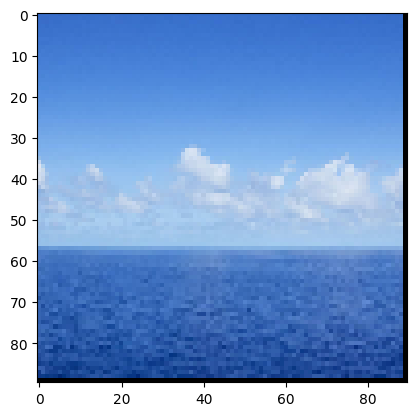

: 

In [ ]:
# test against an image

image = plt.imread(f'./testdata/ocean.jpg')
print(f'image is {image.shape} along first 2 axis')

# crop image down to central square
image = image[:,280:1000,:]

# unswizzle it so we can resize each frame
image_rgb = unswizzle_image(image)
frames = [np.clip(zoom(frame, 0.125), 0, 255).astype('int') for frame in image_rgb]

# comparison image in full color - frames keeps each individual image
image = condense_frames(frames)
image = swizzle_image(image)

plt.imshow(image)

num_points = image.shape[0] * image.shape[1]
print(f'Will have to compute {num_points} datapoints')
datas = [np.ravel(frame) for frame in frames]
axis_size = image.shape[0]

In [ ]:
SAMPLE_COUNT = 5000
idx = 0
reconstructed = [[], [], []]
plt.figure(figsize=(10, 10))
for data in datas:
    length = len(data)
    samples = take_samples(data, SAMPLE_COUNT)
    # print(samples)
    recon = reconstruct(data[samples], length, samples, sparsity=50, mode='cvx')

    reconstructed[idx] = np.resize(recon, (axis_size, axis_size))
    plt.subplot(3, 3, (idx*3)+1) 
    plt.imshow(reconstructed[idx])
    plt.subplot(3, 3, (idx*3)+2)
    plt.imshow(frames[idx])
    plt.subplot(3, 3, (idx*3)+3)
    plt.plot(data-recon)

    idx += 1

plt.tight_layout()
plt.show()

recon_image = swizzle_image(condense_frames(reconstructed))
recon_image = (recon_image - np.min(recon_image)) / (np.max(recon_image) - np.min(recon_image))
plt.figure(figsize=(12, 6))
plt.subplot(1,2,1)
plt.imshow(recon_image)
plt.subplot(1,2,2)
plt.imshow(image)
plt.show()



C:\Users\harry\AppData\Local\Temp\ipykernel_2880\2807356467.py:20: UserWarning: The problem includes expressions that don't support CPP backend. Defaulting to the SCIPY backend for canonicalization.
  problem.solve()
